# Does a better Gini reduce RWA? Scenario-level tests on a corporate IRB book (v2)

Each scenario is a whole-book rating distribution on the same 15-grade master scale, always re-centred to a 1.50% TTC PD.
Every obligor has the same EAD. Each scenario is a calibrated rating system, so its expected Gini follows from the
distribution alone. The matrix varies the good tail (x) and the bad tail (y) of the distribution.

Sign convention: **savings = starting RWA - scenario RWA** (positive = RWA falls).

## 1. Inputs (the only cell to edit)

In [1]:
EAD_TOTAL = 100e9            # EUR; every obligor has the same EAD
LGD = 0.40                   # F-IRB senior unsecured, non-financial corporate
MATURITY = 2.5               # years
PD_FLOOR = 0.0005            # 0.05%
TARGET_PD = 0.015            # TTC PD (obligor-weighted = exposure-weighted, because EAD is equal), held in every scenario
APPLY_106_SCALING = False    # Basel III final / CRR3 basis

GRADES = list(range(1, 16))
OBLIGOR_SHARE_PCT = [2.01, 3.52, 5.53, 8.04, 10.55, 12.56, 13.57, 13.07, 11.06, 8.24, 5.63, 3.42, 1.71, 0.80, 0.30]
START_PD_PCT = [0.050, 0.078, 0.121, 0.189, 0.295, 0.460, 0.717, 1.118, 1.743, 2.717, 4.235, 6.601, 10.289, 16.038, 25.000]

PIVOT = 7.0                                   # centre of grade 7 (median and modal grade of the starting distribution)
GOOD_TAIL_STRETCH = [0.6, 0.8, 1.0, 1.2, 1.4]  # x lever: <1 compresses grades 1-7 towards the pivot, >1 stretches them out
BAD_TAIL_STRETCH = [0.6, 0.8, 1.0, 1.2, 1.4]   # y lever: same for grades 7-15
ROBUSTNESS_PIVOTS = [6.0, 8.0]

## 2. Risk weight, sanity check, master-scale calibration

In [2]:
import numpy as np
import pandas as pd
from scipy.stats import norm
from scipy.optimize import brentq

pd.set_option("display.width", 200)
SCALING = 1.06 if APPLY_106_SCALING else 1.0
obl0 = np.array(OBLIGOR_SHARE_PCT) / np.sum(OBLIGOR_SHARE_PCT)
start_pd = np.array(START_PD_PCT) / 100


def corp_rw(p, lgd=LGD, m=MATURITY, scaling=None):
    """Corporate IRB risk weight: PD-dependent correlation 12%-24%, maturity adjustment, no SME/FI adjustments."""
    scaling = SCALING if scaling is None else scaling
    p = np.asarray(p, dtype=float)
    w = (1 - np.exp(-50 * p)) / (1 - np.exp(-50))
    R = 0.12 * w + 0.24 * (1 - w)
    b = (0.11852 - 0.05478 * np.log(p)) ** 2
    K = lgd * (norm.cdf((norm.ppf(p) + np.sqrt(R) * norm.ppf(0.999)) / np.sqrt(1 - R)) - p) * (1 + (m - 2.5) * b) / (1 - 1.5 * b)
    return 12.5 * K * scaling


rw_check = corp_rw(0.01, lgd=0.45, m=2.5, scaling=1.0)
print(f"Risk-weight sanity check: PD 1%, LGD 45%, M 2.5, no 1.06 factor -> {rw_check:.2%} (expected ~92.3%); "
      f"1.06 applied here: {APPLY_106_SCALING}")
assert abs(rw_check - 0.9232) < 0.0005
_pg = np.exp(np.linspace(np.log(0.0001), np.log(0.5), 20001))
_d2 = np.gradient(np.gradient(corp_rw(_pg), _pg), _pg)
print(f"Risk weight (LGD 40%, M 2.5) concave in PD on [0.01%, 50%]: {bool(np.all(_d2[5:-5] < 0))}")

c0 = brentq(lambda c: np.sum(obl0 * np.maximum(c * start_pd, PD_FLOOR)) - TARGET_PD, 0.1, 10, xtol=1e-15)
Q = np.maximum(c0 * start_pd, PD_FLOOR)          # master scale, fixed in every scenario
RW = corp_rw(Q)
print(f"\nStarting PDs: obligor-weighted {np.sum(obl0*start_pd):.4%}. Scale factor c0 = {c0:.6f}; "
      f"grades on the floor: {[g for g, p in zip(GRADES, c0*start_pd) if p < PD_FLOOR]} "
      f"(grade 1 would be {c0*start_pd[0]:.4%})")
print(f"Calibrated starting model: obligor-weighted PD {np.sum(obl0*Q):.6%} (= exposure-weighted PD, equal EAD)")
print(pd.DataFrame({"grade": GRADES, "obligor_share_%": obl0 * 100, "PD_%": Q * 100, "RW_%": RW * 100}).round(4).to_string(index=False))

Risk-weight sanity check: PD 1%, LGD 45%, M 2.5, no 1.06 factor -> 92.32% (expected ~92.3%); 1.06 applied here: False
Risk weight (LGD 40%, M 2.5) concave in PD on [0.01%, 50%]: True

Starting PDs: obligor-weighted 1.6179%. Scale factor c0 = 0.927093; grades on the floor: [1] (grade 1 would be 0.0464%)
Calibrated starting model: obligor-weighted PD 1.500000% (= exposure-weighted PD, equal EAD)
 grade  obligor_share_%    PD_%     RW_%
     1           2.0098  0.0500  17.4677
     2           3.5196  0.0723  21.7788
     3           5.5294  0.1122  28.1784
     4           8.0392  0.1752  36.2830
     5          10.5489  0.2735  46.0899
     6          12.5587  0.4265  57.4780
     7          13.5686  0.6647  70.0450
     8          13.0687  1.0365  83.1136
     9          11.0589  1.6159  95.9951
    10           8.2392  2.5189 108.8068
    11           5.6294  3.9262 123.3727
    12           3.4197  6.1197 142.8879
    13           1.7098  9.5389 168.6477
    14           0.7999 14.86

## 3. Gini and RWA of a rating distribution
For a calibrated rating system with average PD p, expected Gini = MD / (2 p (1 - p)), where MD is the mean absolute
difference between the PDs of two randomly drawn obligors. The cell checks this identity against the direct AUC formula.

In [3]:
def gini(n, q=Q):
    """Expected accuracy ratio (2*AUC-1) of a calibrated graded model: defaulters n*q, non-defaulters n*(1-q), ties half."""
    D, ND = n * q, n * (1 - q)
    nd_better = np.concatenate([[0.0], np.cumsum(ND)[:-1]])
    nd_worse = ND.sum() - nd_better - ND
    return np.sum(D * (nd_better - nd_worse)) / (D.sum() * ND.sum())


def mean_abs_diff(n, q=Q):
    return np.sum(np.outer(n, n) * np.abs(q[:, None] - q[None, :]))


def rwa(n, q=Q):
    return EAD_TOTAL * np.sum(n * corp_rw(q))


G0, RWA0 = gini(obl0), rwa(obl0)
print(f"Starting model: RWA EUR {RWA0/1e9:.3f}bn (average RW {RWA0/EAD_TOTAL:.2%}), Gini {G0:.4%}")
print(f"Identity check: MD/(2p(1-p)) = {mean_abs_diff(obl0)/(2*TARGET_PD*(1-TARGET_PD)):.10%} vs direct {G0:.10%}")

Starting model: RWA EUR 74.558bn (average RW 74.56%), Gini 62.6972%
Identity check: MD/(2p(1-p)) = 62.6971639893% vs direct 62.6971639893%


## 4. Scenario generator: stretch the good tail by a, the bad tail by b, re-centre to 1.50%

In [4]:
def scenario(a, b, pivot=PIVOT, base=obl0, recentre=True):
    """Return (shares over 15 grades, shift s in notches). Histogram mass is uniform inside [g-0.5, g+0.5].
    recentre=False returns the stretched distribution before the mean-restoring shift (used only for diagnostics)."""
    def fmap(x):
        return np.where(x < pivot, pivot - a * (pivot - x), pivot + b * (x - pivot))

    pieces = []
    for g in range(1, 16):
        lo, hi = g - 0.5, g + 0.5
        cuts = [lo, pivot, hi] if lo < pivot < hi else [lo, hi]
        for l, h in zip(cuts[:-1], cuts[1:]):
            pieces.append((base[g - 1] * (h - l), float(fmap(l)), float(fmap(h))))

    def rebin(s):
        out = np.zeros(15)
        for m, L, H in pieces:
            L, H = L + s, H + s
            for k in range(15):
                bl = -np.inf if k == 0 else k + 0.5
                bh = np.inf if k == 14 else k + 1.5
                ov = max(0.0, min(H, bh) - max(L, bl))
                out[k] += m * ov / (H - L)
        return out

    if not recentre:
        return rebin(0.0), 0.0
    s = brentq(lambda s: np.sum(rebin(s) * Q) - TARGET_PD, -8, 8, xtol=1e-13)
    n = rebin(s)
    assert abs(n.sum() - 1) < 1e-12 and abs(np.sum(n * Q) - TARGET_PD) < 1e-12
    return n, s


def stoploss(n):
    """E[(PD - t)+] at every master-scale PD t. Equal means + higher everywhere = a mean-preserving spread."""
    return np.array([np.sum(n * np.maximum(Q - t, 0)) for t in Q])


def cap_class(n, tol=1e-12):
    """'spread': the scenario's expected CAP curve lies on or above the start's everywhere (mean-preserving spread);
    'contraction': on or below everywhere; 'crossing': the curves cross."""
    d = stoploss(n) - stoploss(obl0)
    if np.all(np.abs(d) <= tol):
        return "start"
    return "spread" if np.all(d >= -tol) else ("contraction" if np.all(d <= tol) else "crossing")


def cap_curve(n):
    """Expected CAP of a calibrated model: obligors sorted worst first; x = share of obligors, y = share of defaults."""
    order = np.arange(14, -1, -1)
    x = np.concatenate([[0], np.cumsum(n[order])])
    y = np.concatenate([[0], np.cumsum((n * Q)[order]) / np.sum(n * Q)])
    return x, y


def outcome(dg, sav, tol_g=1e-6, tol_r=1e-3):
    if abs(dg) < tol_g and abs(sav) < tol_r:
        return "start"
    return ("Gini up" if dg > 0 else "Gini down") + ", " + ("RWA down" if sav > 0 else "RWA up")


def run_grid(pivot):
    rows, dists = [], {}
    for a in GOOD_TAIL_STRETCH:
        for b in BAD_TAIL_STRETCH:
            n, s = scenario(a, b, pivot)
            g, r = gini(n), rwa(n)
            sav = (RWA0 - r) / 1e6
            dg = 100 * (g - G0)
            rows.append(dict(a=a, b=b, shift_notches=s, gini_pct=100 * g, dGini_pp=dg, RWA_EURbn=r / 1e9, savings_EURm=sav,
                             EURm_per_Gini_pt=sav / dg if abs(dg) > 1e-9 else np.nan, outcome=outcome(dg, sav),
                             cap=cap_class(n), share_grade1_pct=100 * n[0], share_13_15_pct=100 * n[12:].sum(), share_1_6_pct=100 * n[:6].sum(),
                             PD_pct=100 * np.sum(n * Q)))
            dists[(a, b)] = n
    return pd.DataFrame(rows), dists


grid, DIST = run_grid(PIVOT)
assert np.allclose(DIST[(1.0, 1.0)], obl0) and abs(grid.query("a==1 and b==1").savings_EURm.iloc[0]) < 1e-6
print("Scenario grid (pivot = centre of grade 7). a = good-tail stretch, b = bad-tail stretch")
print(grid.round(3).to_string(index=False))

Scenario grid (pivot = centre of grade 7). a = good-tail stretch, b = bad-tail stretch
  a   b  shift_notches  gini_pct  dGini_pp  RWA_EURbn  savings_EURm  EURm_per_Gini_pt           outcome         cap  share_grade1_pct  share_13_15_pct  share_1_6_pct  PD_pct
0.6 0.6          1.117    41.650   -21.047     85.723    -11165.665           530.506 Gini down, RWA up contraction             0.000            0.456         17.535     1.5
0.6 0.8          0.557    50.780   -11.917     82.103     -7545.715           633.207 Gini down, RWA up contraction             0.000            1.649         26.887     1.5
0.6 1.0         -0.084    59.271    -3.426     77.643     -3085.026           900.391 Gini down, RWA up contraction             0.000            2.667         39.769     1.5
0.6 1.2         -0.822    67.165     4.468     72.322      2235.169           500.233 Gini up, RWA down    crossing             0.000            3.602         52.630     1.5
0.6 1.4         -1.563    73.199    10.502 

## 5. Outcome matrices

In [5]:
piv = lambda col: grid.pivot(index="b", columns="a", values=col).sort_index(ascending=False)
print("RWA savings, EUR m (rows: bad-tail stretch b, top = most stretched; columns: good-tail stretch a)")
print(piv("savings_EURm").round(0).to_string())
print("\nGini change, pp")
print(piv("dGini_pp").round(2).to_string())
print("\nOutcome")
print(piv("outcome").to_string())
print("\nEUR m of RWA saved per Gini point")
print(piv("EURm_per_Gini_pt").round(0).to_string())
print("\nExpected CAP curve vs the start")
print(piv("cap").to_string())
print("\nShift needed to restore 1.50% (notches; negative = whole book moved to better grades)")
print(piv("shift_notches").round(2).to_string())
print("\nShare of obligors in grade 1 (on the floor), %")
print(piv("share_grade1_pct").round(1).to_string())

RWA savings, EUR m (rows: bad-tail stretch b, top = most stretched; columns: good-tail stretch a)
a        0.6     0.8     1.0      1.2      1.4
b                                             
1.4   7429.0  8768.0  9856.0  10654.0  11323.0
1.2   2235.0  3812.0  5154.0   6233.0   7118.0
1.0  -3085.0 -1438.0     0.0   1433.0   2556.0
0.8  -7546.0 -5834.0 -4172.0  -2735.0  -1464.0
0.6 -11166.0 -9467.0 -7794.0  -6231.0  -4844.0

Gini change, pp
a      0.6    0.8    1.0    1.2    1.4
b                                     
1.4  10.50  11.59  12.40  12.95  13.39
1.2   4.47   6.01   7.18   8.05   8.72
1.0  -3.43  -1.47   0.00   1.38   2.39
0.8 -11.92  -9.46  -7.43  -5.87  -4.59
0.6 -21.05 -18.09 -15.67 -13.73 -12.15

Outcome
a                  0.6                0.8                1.0                1.2                1.4
b                                                                                                 
1.4  Gini up, RWA down  Gini up, RWA down  Gini up, RWA down  Gini up, RWA d

## 6. Robustness: pivot at grade 6 and grade 8, and the pre-registered expectations

In [6]:
for pv in ROBUSTNESS_PIVOTS:
    gr, _ = run_grid(pv)
    changed = (gr.outcome.values != grid.outcome.values).sum()
    print(f"Pivot {pv}: {changed} of 24 cells change outcome class; savings range {gr.savings_EURm.min():,.0f} to {gr.savings_EURm.max():,.0f} EUR m")
    print(gr.pivot(index="b", columns="a", values="outcome").sort_index(ascending=False).to_string())

g = grid.set_index(["a", "b"])
others = grid[~((grid.a == 1) & (grid.b == 1))]
diag = grid[(grid.a == grid.b) & (grid.a != 1)]
checks = {
    "V2 Gini rises with a (every b)": all(np.all(np.diff(grid[grid.b == b].sort_values("a").gini_pct) > 0) for b in BAD_TAIL_STRETCH),
    "V2 Gini rises with b (every a)": all(np.all(np.diff(grid[grid.a == a].sort_values("b").gini_pct) > 0) for a in GOOD_TAIL_STRETCH),
    "V2 b moves Gini more than a (range over grid)": bool(piv("gini_pct").max(axis=0).sub(piv("gini_pct").min(axis=0)).mean()
                                                         > piv("gini_pct").max(axis=1).sub(piv("gini_pct").min(axis=1)).mean()),
    "V3 savings rise with a (every b)": all(np.all(np.diff(grid[grid.b == b].sort_values("a").savings_EURm) > 0) for b in BAD_TAIL_STRETCH),
    "V4 savings rise with b (every a)": all(np.all(np.diff(grid[grid.a == a].sort_values("b").savings_EURm) > 0) for a in GOOD_TAIL_STRETCH),
    "V5 diagonal: Gini and RWA move in opposite directions": bool(np.all(np.sign(diag.dGini_pp) == np.sign(diag.savings_EURm))),
    "V6 at least one cell where Gini and RWA move the same way": bool((others.outcome.isin(["Gini up, RWA up", "Gini down, RWA down"])).any()),
    "V7 EUR m per Gini point varies by > 2x": bool(others.EURm_per_Gini_pt.abs().max() > 2 * others.EURm_per_Gini_pt.abs().min()),
}
v1 = []
for a in GOOD_TAIL_STRETCH:
    for b in BAD_TAIL_STRETCH:
        n_pre, _ = scenario(a, b, recentre=False)
        v1.append(100 * abs(gini(DIST[(a, b)]) - gini(n_pre)))
checks["V1 the re-centring shift moves Gini by < 10% of the grid's Gini range"] = bool(max(v1) < 0.1 * (grid.gini_pct.max() - grid.gini_pct.min()))
print(f"V1 detail: re-centring changes Gini by at most {max(v1):.2f} pp; Gini range across the grid {grid.gini_pct.max()-grid.gini_pct.min():.1f} pp")
print("\nPre-registered expectations:")
for k, v in checks.items():
    print(f"  {'HOLDS ' if v else 'BROKEN'}  {k}")
print("\nOutcome counts:", others.outcome.value_counts().to_dict())

by_cap = others.groupby("cap").agg(cells=("a", "size"), outcomes=("outcome", lambda x: dict(x.value_counts())),
                                   savings_min=("savings_EURm", "min"), savings_max=("savings_EURm", "max"))
print("\nOutcome by CAP relation:")
print(by_cap.to_string())
slope = np.sum(others.dGini_pp * others.savings_EURm) / np.sum(others.dGini_pp ** 2)
r2 = 1 - np.sum((others.savings_EURm - slope * others.dGini_pp) ** 2) / np.sum(others.savings_EURm ** 2)
print(f"\nLine through the start: savings = {slope:,.0f} EUR m x dGini(pp); R^2 (uncentred) {r2:.3f}")
print(f"EUR m per Gini point across the 24 cells: min {others.EURm_per_Gini_pt.min():,.0f}, median {others.EURm_per_Gini_pt.median():,.0f}, max {others.EURm_per_Gini_pt.max():,.0f}")
for lab, sub in [("only the good tail changes (b = 1)", others[others.b == 1]), ("only the bad tail changes (a = 1)", others[others.a == 1]),
                 ("both tails stretched or both compressed", others[(others.a - 1) * (others.b - 1) > 0]),
                 ("one tail stretched, the other compressed", others[(others.a - 1) * (others.b - 1) < 0])]:
    print(f"  {lab}: EUR m per Gini point {sub.EURm_per_Gini_pt.min():,.0f} to {sub.EURm_per_Gini_pt.max():,.0f}")

Pivot 6.0: 0 of 24 cells change outcome class; savings range -11,166 to 11,323 EUR m
a                  0.6                0.8                1.0                1.2                1.4
b                                                                                                 
1.4  Gini up, RWA down  Gini up, RWA down  Gini up, RWA down  Gini up, RWA down  Gini up, RWA down
1.2  Gini up, RWA down  Gini up, RWA down  Gini up, RWA down  Gini up, RWA down  Gini up, RWA down
1.0  Gini down, RWA up  Gini down, RWA up              start  Gini up, RWA down  Gini up, RWA down
0.8  Gini down, RWA up  Gini down, RWA up  Gini down, RWA up  Gini down, RWA up  Gini down, RWA up
0.6  Gini down, RWA up  Gini down, RWA up  Gini down, RWA up  Gini down, RWA up  Gini down, RWA up


Pivot 8.0: 2 of 24 cells change outcome class; savings range -11,166 to 11,323 EUR m
a                  0.6                0.8                1.0                1.2                  1.4
b                                                                                                   
1.4  Gini up, RWA down  Gini up, RWA down  Gini up, RWA down  Gini up, RWA down    Gini up, RWA down
1.2    Gini up, RWA up  Gini up, RWA down  Gini up, RWA down  Gini up, RWA down    Gini up, RWA down
1.0  Gini down, RWA up  Gini down, RWA up              start  Gini up, RWA down    Gini up, RWA down
0.8  Gini down, RWA up  Gini down, RWA up  Gini down, RWA up  Gini down, RWA up  Gini down, RWA down
0.6  Gini down, RWA up  Gini down, RWA up  Gini down, RWA up  Gini down, RWA up    Gini down, RWA up
V1 detail: re-centring changes Gini by at most 2.60 pp; Gini range across the grid 34.4 pp

Pre-registered expectations:
  HOLDS   V2 Gini rises with a (every b)
  HOLDS   V2 Gini rises with b (every a)
  HOL

## 7. Post-hoc (not pre-registered): the same family at finer resolution
a and b from 0.5 to 1.5 in steps of 0.05, pivot at grades 6, 7 and 8. Every point is computed; nothing is interpolated.
Purpose: find where, inside this family, Gini and RWA can move in the same direction.

In [7]:
FINE = np.round(np.arange(0.5, 1.5001, 0.05), 2)
fine_rows = []
for pv in [6.0, 7.0, 8.0]:
    for a in FINE:
        for b in FINE:
            if a == 1 and b == 1:
                continue
            n, sh = scenario(a, b, pv)
            dg, sv = 100 * (gini(n) - G0), (RWA0 - rwa(n)) / 1e6
            fine_rows.append(dict(pivot=pv, a=a, b=b, dGini_pp=dg, savings_EURm=sv, outcome=outcome(dg, sv), cap=cap_class(n)))
fine = pd.DataFrame(fine_rows)
fine["same_direction"] = fine.outcome.isin(["Gini up, RWA up", "Gini down, RWA down"])
print(fine.groupby("pivot").same_direction.agg(["sum", "size"]).rename(columns={"sum": "Gini and RWA same direction", "size": "points"}).to_string())
dv = fine[fine.same_direction]
print(f"\nAll same-direction points: CAP relation {dv.cap.value_counts().to_dict()}; |dGini| max {dv.dGini_pp.abs().max():.2f} pp; "
      f"one tail stretched and the other compressed in {int(((dv.a-1)*(dv.b-1) < 0).sum())} of {len(dv)}")
print(f"Largest RWA rise with a Gini gain: EUR {-dv[dv.dGini_pp > 0].savings_EURm.min():,.0f}m (dGini {dv.loc[dv[dv.dGini_pp > 0].savings_EURm.idxmin(), 'dGini_pp']:+.2f} pp)")
print(f"Largest RWA fall with a Gini loss: EUR {dv[dv.dGini_pp < 0].savings_EURm.max():,.0f}m (dGini {dv.loc[dv[dv.dGini_pp < 0].savings_EURm.idxmax(), 'dGini_pp']:+.2f} pp)")
print("Outcome by CAP relation, all fine points:")
print(fine.groupby("cap").outcome.value_counts().unstack(fill_value=0).to_string())
print(f"Share of points with |dGini| > 3.7 pp where Gini and RWA move the same way: "
      f"{fine[(fine.dGini_pp.abs() > 3.7)].same_direction.mean():.0%}")

       Gini and RWA same direction  points
pivot                                     
6.0                              8     440
7.0                             12     440
8.0                             22     440

All same-direction points: CAP relation {'crossing': 42}; |dGini| max 3.70 pp; one tail stretched and the other compressed in 42 of 42
Largest RWA rise with a Gini gain: EUR 1,010m (dGini +0.38 pp)
Largest RWA fall with a Gini loss: EUR 1,562m (dGini -0.88 pp)
Outcome by CAP relation, all fine points:
outcome      Gini down, RWA down  Gini down, RWA up  Gini up, RWA down  Gini up, RWA up
cap                                                                                    
contraction                    0                448                  0                0
crossing                      28                188                173               14
spread                         0                  0                469                0
Share of points with |dGini| > 3.7 pp whe

## 8. Charts

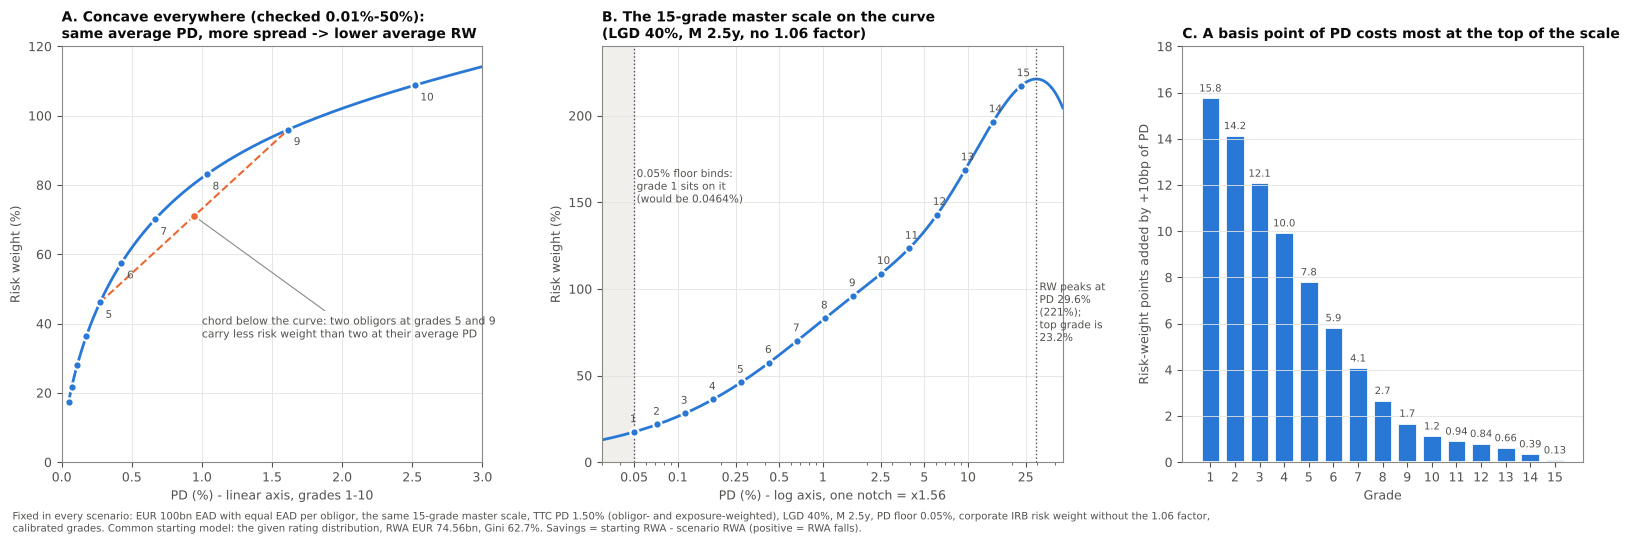

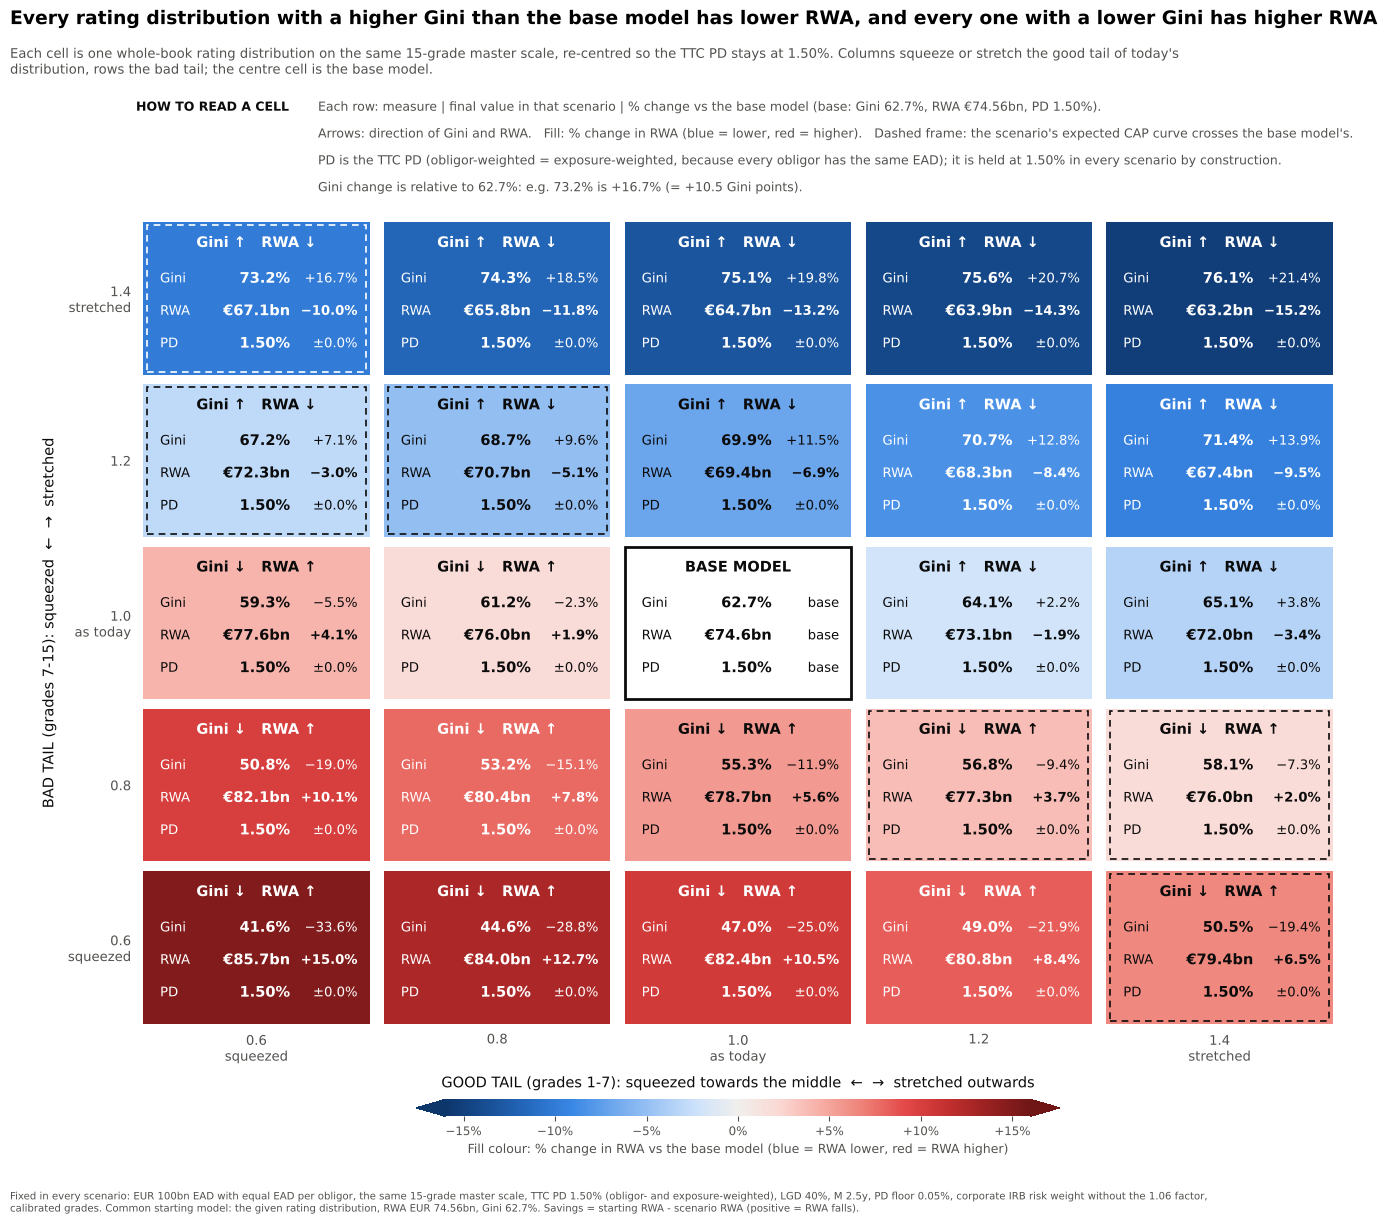

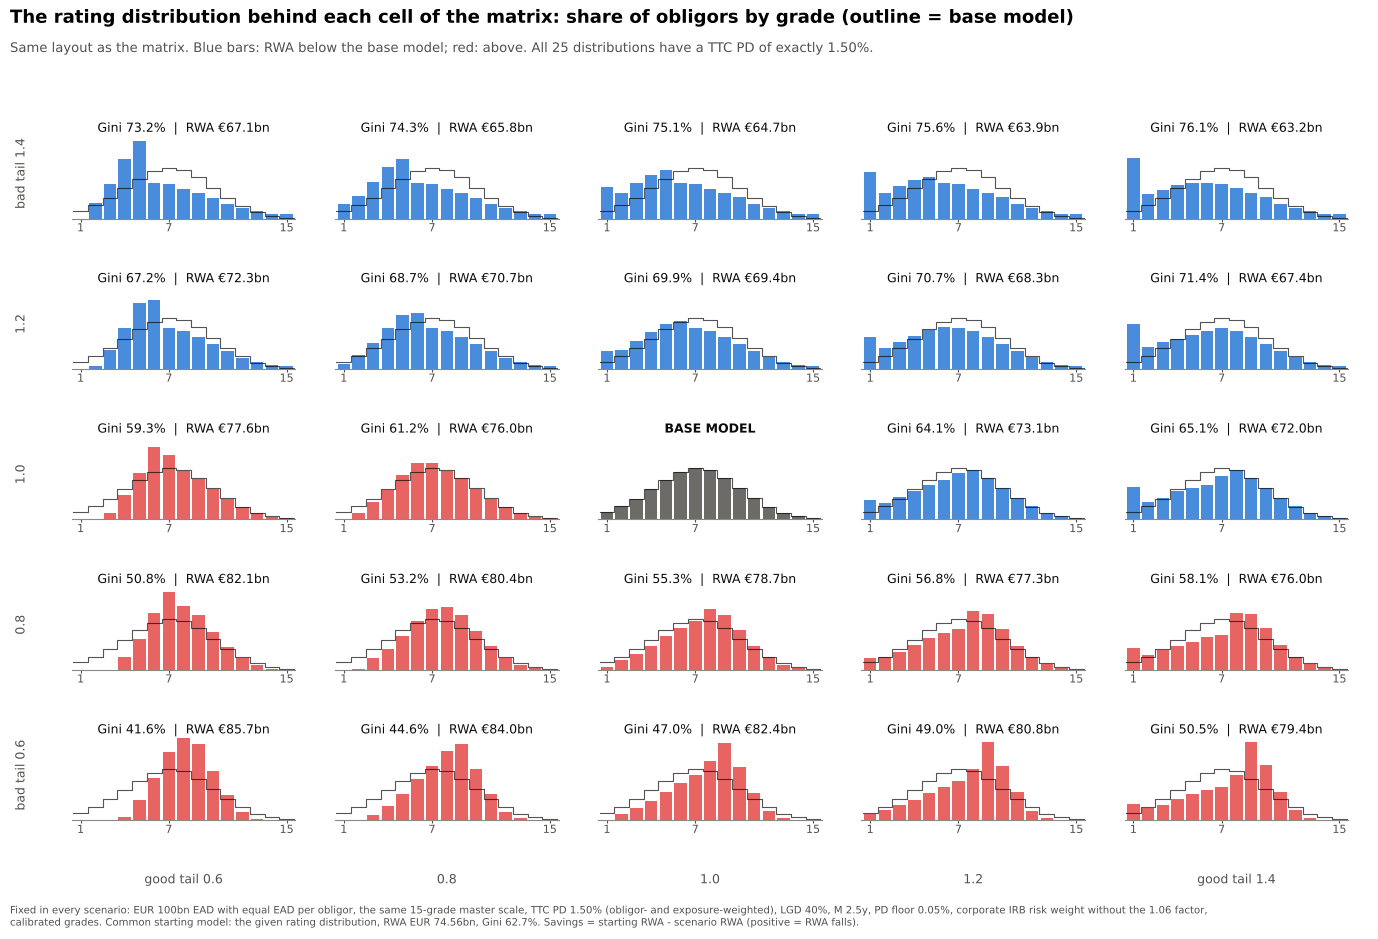

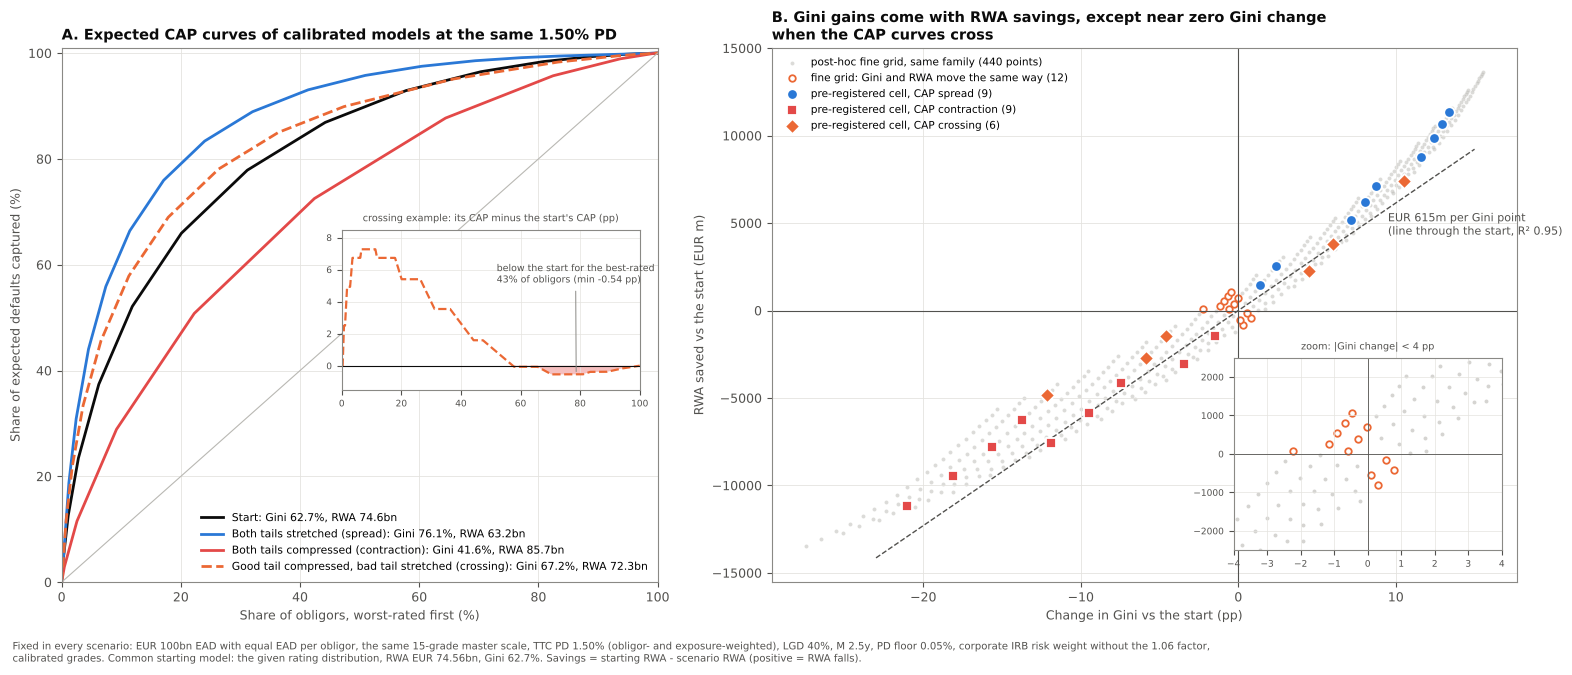

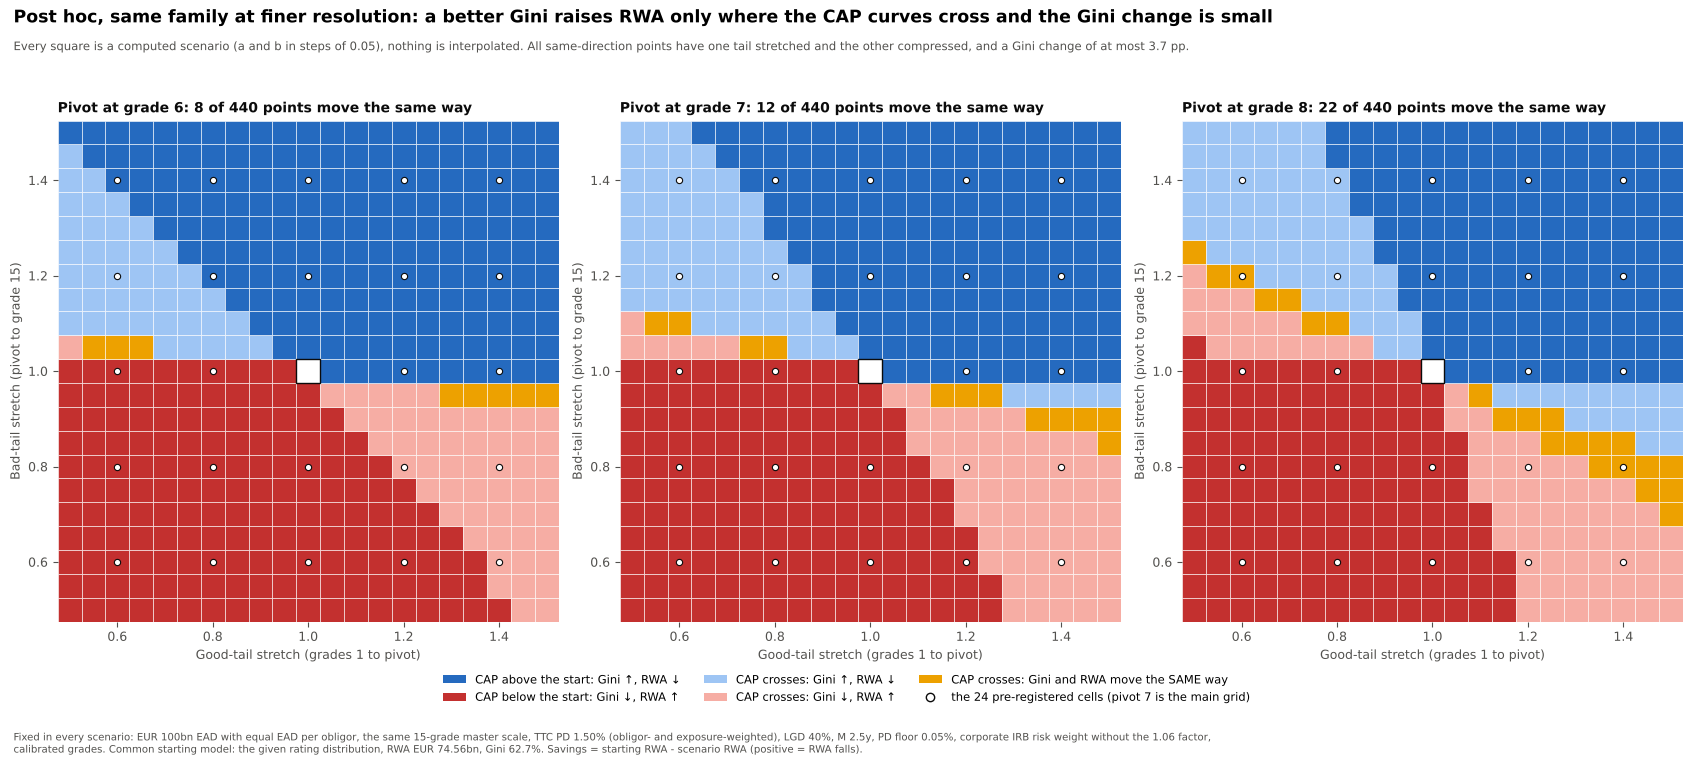

Saved v2 figures and CSVs


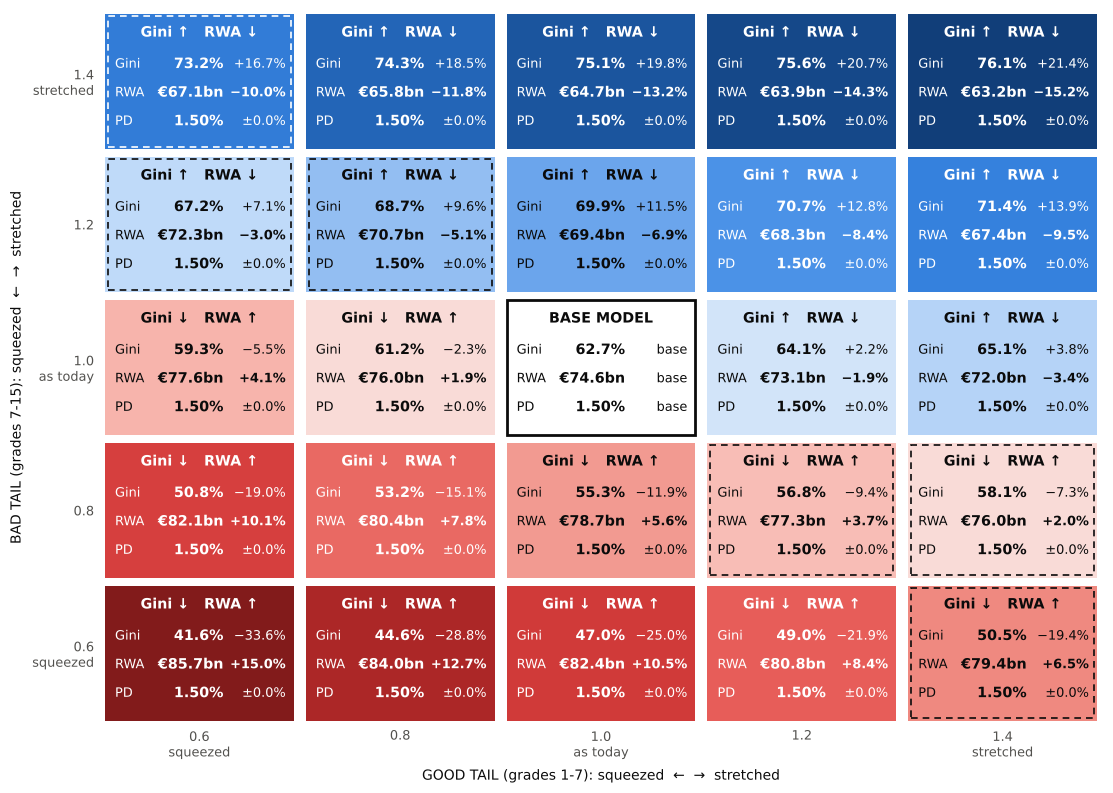

In [8]:
import matplotlib
try:
    get_ipython()  # noqa: F821
except NameError:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm, to_rgb
from matplotlib.patches import Rectangle, Patch
from scipy.optimize import minimize_scalar

INK, INK2, MUTED, GRIDC, GREY = "#0b0b0b", "#52514e", "#8a8985", "#e4e3df", "#b9b8b3"
BLUE, ORANGE, AQUA, RED = "#2a78d6", "#eb6834", "#1baf7a", "#e34948"
BLUE_ARM = ["#f0efec", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
RED_ARM = ["#f0efec", "#fbd8d3", "#f6ada4", "#ee8178", "#e34948", "#c3302f", "#9a2121", "#701616"]
DIV = LinearSegmentedColormap.from_list("savings", RED_ARM[::-1] + BLUE_ARM[1:])
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 9, "axes.edgecolor": MUTED, "axes.labelcolor": INK2,
                     "xtick.color": INK2, "ytick.color": INK2, "axes.titlecolor": INK, "figure.facecolor": "white"})
FOOT = (f"Fixed in every scenario: EUR 100bn EAD with equal EAD per obligor, the same 15-grade master scale, TTC PD 1.50% (obligor- and exposure-weighted), "
        f"LGD 40%, M 2.5y, PD floor 0.05%, corporate IRB risk weight without the 1.06 factor,\ncalibrated grades. "
        f"Common starting model: the given rating distribution, RWA EUR {RWA0/1e9:.2f}bn, Gini {G0:.1%}. Savings = starting RWA - scenario RWA (positive = RWA falls).")
ALAB = ["0.6\ncompressed", "0.8", "1.0\nas today", "1.2", "1.4\nstretched"]


def _lum(c):
    r, g, b = to_rgb(c)
    f = lambda x: x / 12.92 if x <= 0.04045 else ((x + 0.055) / 1.055) ** 2.4
    return 0.2126 * f(r) + 0.7152 * f(g) + 0.0722 * f(b)


# ---------- Figure 1: risk-weight curve with the master scale
fig, axs = plt.subplots(1, 3, figsize=(16, 5.2), gridspec_kw=dict(width_ratios=[1.05, 1.15, 1]))
ax = axs[0]
pp = np.linspace(0.0005, 0.03, 400)
ax.plot(pp * 100, corp_rw(pp) * 100, color=BLUE, lw=2)
sel = Q <= 0.03
ax.scatter(Q[sel] * 100, corp_rw(Q[sel]) * 100, s=36, color=BLUE, zorder=3, edgecolor="white", lw=1.5)
for gg, q in zip(np.array(GRADES)[sel], Q[sel]):
    if gg >= 5:
        ax.annotate(str(gg), (q * 100, corp_rw(q) * 100), xytext=(4, -11), textcoords="offset points", fontsize=7.5, color=INK2)
a_, b_ = Q[4], Q[8]
ax.plot([a_ * 100, b_ * 100], [corp_rw(a_) * 100, corp_rw(b_) * 100], color=ORANGE, lw=1.5, ls="--")
mid = 0.5 * (a_ + b_)
ax.scatter([mid * 100], [0.5 * (corp_rw(a_) + corp_rw(b_)) * 100], s=40, color=ORANGE, zorder=4, edgecolor="white", lw=1.5)
ax.annotate("chord below the curve: two obligors at grades 5 and 9\ncarry less risk weight than two at their average PD",
            (mid * 100, 0.5 * (corp_rw(a_) + corp_rw(b_)) * 100), xytext=(1.0, 36), fontsize=7.8, color=INK2,
            arrowprops=dict(arrowstyle="-", color=MUTED, lw=.8))
ax.set_xlabel("PD (%) - linear axis, grades 1-10"); ax.set_ylabel("Risk weight (%)")
ax.set_title("A. Concave everywhere (checked 0.01%-50%):\nsame average PD, more spread -> lower average RW", loc="left", fontsize=10, weight="bold")
ax.grid(color=GRIDC, lw=.6); ax.set_xlim(0, 3); ax.set_ylim(0, 120)
ax = axs[1]
pg = np.exp(np.linspace(np.log(0.0003), np.log(0.45), 500))
ax.plot(pg * 100, corp_rw(pg) * 100, color=BLUE, lw=2)
ax.scatter(Q * 100, corp_rw(Q) * 100, s=36, color=BLUE, zorder=3, edgecolor="white", lw=1.5)
for gg, q in zip(GRADES, Q):
    ax.annotate(str(gg), (q * 100, corp_rw(q) * 100), xytext=(-3, 7), textcoords="offset points", fontsize=7.5, color=INK2)
ax.axvspan(0.03, PD_FLOOR * 100, color="#f0efec", zorder=0)
ax.axvline(PD_FLOOR * 100, color=INK2, lw=1, ls=":")
ax.text(0.052, 150, "0.05% floor binds:\ngrade 1 sits on it\n(would be 0.0464%)", fontsize=7.6, color=INK2)
pk = minimize_scalar(lambda x: -corp_rw(x), bounds=(0.1, 0.5), method="bounded", options=dict(xatol=1e-8)).x
ax.axvline(pk * 100, color=INK2, lw=1, ls=":")
ax.text(pk * 100 * 1.05, 70, f"RW peaks at\nPD {pk:.1%}\n({corp_rw(pk):.0%});\ntop grade is\n{Q[-1]:.1%}", fontsize=7.6, color=INK2)
ax.set_xscale("log"); ax.set_xlim(0.03, 45); ax.set_ylim(0, 240)
ax.set_xticks([0.05, 0.1, 0.25, 0.5, 1, 2.5, 5, 10, 25]); ax.set_xticklabels(["0.05", "0.1", "0.25", "0.5", "1", "2.5", "5", "10", "25"])
ax.set_xlabel("PD (%) - log axis, one notch = x1.56"); ax.set_ylabel("Risk weight (%)")
ax.set_title("B. The 15-grade master scale on the curve\n(LGD 40%, M 2.5y, no 1.06 factor)", loc="left", fontsize=10, weight="bold")
ax.grid(color=GRIDC, lw=.6)
ax = axs[2]
per10 = (corp_rw(Q + 0.001) - corp_rw(Q)) * 100
ax.bar(np.arange(1, 16), per10, width=.8, color=BLUE, edgecolor="white", lw=2)
for i, v in enumerate(per10):
    ax.text(i + 1, v + .25, f"{v:.1f}" if v >= 1 else f"{v:.2f}", ha="center", fontsize=7.2, color=INK2)
ax.set_xticks(range(1, 16)); ax.set_xlabel("Grade")
ax.set_ylabel("Risk-weight points added by +10bp of PD")
ax.set_title("C. A basis point of PD costs most at the top of the scale", loc="left", fontsize=10, weight="bold")
ax.set_ylim(0, 18); ax.grid(axis="y", color=GRIDC, lw=.6)
fig.text(0.01, -0.03, FOOT, fontsize=7.3, color=INK2)
fig.tight_layout()
fig.savefig("v2_fig1_risk_weight_curve.png", dpi=200, bbox_inches="tight"); plt.show()

# ---------- Figure 2: the outcome matrix (each cell = final Gini, RWA, PD and % change vs base)
A_, B_ = GOOD_TAIL_STRETCH, BAD_TAIL_STRETCH
PCT_MAX = 16
pnorm = TwoSlopeNorm(vmin=-PCT_MAX, vcenter=0, vmax=PCT_MAX)
ARROW = {"Gini up": "Gini ↑", "Gini down": "Gini ↓", "RWA down": "RWA ↓", "RWA up": "RWA ↑"}
grid["RWA_pct_change"] = 100 * (grid.RWA_EURbn * 1e9 / RWA0 - 1)
grid["Gini_pct_change"] = 100 * (grid.gini_pct / (100 * G0) - 1)
grid["PD_pct_change"] = 100 * (grid.PD_pct / (100 * TARGET_PD) - 1)
fmt_pct = lambda v: ("+" if v > 0.05 else ("−" if v < -0.05 else "±")) + f"{abs(v):.1f}%"


def draw_cell(ax, i, j, r, fs=1.0, show_outcome=True, xs=(.1, .64, .92)):
    """One cell = a three-row table: label | final value | % change vs base."""
    base = r.outcome == "start"
    fc = "white" if base else DIV(pnorm(-r.RWA_pct_change))
    tc = INK if (base or _lum(fc) >= 0.33) else "white"
    ax.add_patch(Rectangle((i + .03, j + .03), .94, .94, facecolor=fc, edgecolor=INK if base else "none", lw=2 if base else 0))
    if r.cap == "crossing":
        ax.add_patch(Rectangle((i + .045, j + .045), .91, .91, facecolor="none", edgecolor=tc, lw=1.2, ls=(0, (4, 3))))
    head = "BASE MODEL" if base else f"{ARROW[r.outcome.split(', ')[0]]}   {ARROW[r.outcome.split(', ')[1]]}"
    if show_outcome or base:
        ax.text(i + .5, j + .84, head, ha="center", va="center", fontsize=10.5 * fs, weight="bold", color=tc)
    rows = [("Gini", f"{r.gini_pct:.1f}%", r.Gini_pct_change),
            ("RWA", f"€{r.RWA_EURbn:.1f}bn", r.RWA_pct_change),
            ("PD", f"{r.PD_pct:.2f}%", r.PD_pct_change)]
    for k, (lab, val, chg) in enumerate(rows):
        y = j + .62 - k * .2
        ax.text(i + xs[0], y, lab, ha="left", va="center", fontsize=9.5 * fs, color=tc)
        ax.text(i + xs[1], y, val, ha="right", va="center", fontsize=10.5 * fs, weight="bold", color=tc)
        ax.text(i + xs[2], y, "base" if base else fmt_pct(chg), ha="right", va="center", fontsize=9.5 * fs, color=tc,
                weight="bold" if (lab == "RWA" and not base) else "normal")


def setup_matrix_axes(ax, fs=1.0):
    ax.set_xlim(0, 5); ax.set_ylim(0, 5)
    labs = ["0.6\nsqueezed", "0.8", "1.0\nas today", "1.2", "1.4\nstretched"]
    ax.set_xticks(np.arange(5) + .5); ax.set_xticklabels(labs, fontsize=9.5 * fs)
    ax.set_yticks(np.arange(5) + .5); ax.set_yticklabels(labs, fontsize=9.5 * fs)
    ax.tick_params(length=0)
    for sp in ax.spines.values():
        sp.set_visible(False)
    ax.set_xlabel("GOOD TAIL (grades 1-7): squeezed towards the middle  ←  →  stretched outwards", fontsize=10.5 * fs, color=INK, labelpad=8)
    ax.set_ylabel("BAD TAIL (grades 7-15): squeezed  ←  →  stretched", fontsize=10.5 * fs, color=INK, labelpad=8)


fig = plt.figure(figsize=(14, 12.2))
axm = fig.add_axes([0.1, 0.15, 0.86, 0.665])
for i, a in enumerate(A_):
    for j, b in enumerate(B_):
        draw_cell(axm, i, j, grid[(grid.a == a) & (grid.b == b)].iloc[0])
setup_matrix_axes(axm)
fig.text(0.01, 0.985, "Every rating distribution with a higher Gini than the base model has lower RWA, and every one with a lower Gini has higher RWA",
         fontsize=13.5, weight="bold", va="top")
fig.text(0.01, 0.955, "Each cell is one whole-book rating distribution on the same 15-grade master scale, re-centred so the TTC PD stays at 1.50%. "
         "Columns squeeze or stretch the good tail of today's\ndistribution, rows the bad tail; the centre cell is the base model.",
         fontsize=9.5, color=INK2, va="top")
# key
kx, ky = 0.1, 0.905
fig.text(kx, ky, "HOW TO READ A CELL", fontsize=9, weight="bold", color=INK, va="center")
fig.text(kx + 0.13, ky, "Each row: measure | final value in that scenario | % change vs the base model "
         "(base: Gini 62.7%, RWA €74.56bn, PD 1.50%).", fontsize=9, color=INK2, va="center")
fig.text(kx + 0.13, ky - 0.066, "Gini change is relative to 62.7%: e.g. 73.2% is +16.7% (= +10.5 Gini points).",
         fontsize=9, color=INK2, va="center")
fig.text(kx + 0.13, ky - 0.022, "Arrows: direction of Gini and RWA.   Fill: % change in RWA (blue = lower, red = higher).   "
         "Dashed frame: the scenario's expected CAP curve crosses the base model's.", fontsize=9, color=INK2, va="center")
fig.text(kx + 0.13, ky - 0.044, "PD is the TTC PD (obligor-weighted = exposure-weighted, because every obligor has the same EAD); "
         "it is held at 1.50% in every scenario by construction.", fontsize=9, color=INK2, va="center")
sm = plt.cm.ScalarMappable(cmap=DIV.reversed(), norm=TwoSlopeNorm(vmin=-PCT_MAX, vcenter=0, vmax=PCT_MAX))
cax = fig.add_axes([0.3, 0.078, 0.46, 0.014])
cb = fig.colorbar(sm, cax=cax, orientation="horizontal", extend="both")
cb.set_ticks([-15, -10, -5, 0, 5, 10, 15]); cb.set_ticklabels(["−15%", "−10%", "−5%", "0%", "+5%", "+10%", "+15%"])
cb.outline.set_visible(False); cb.ax.tick_params(labelsize=8.5)
cb.set_label("Fill colour: % change in RWA vs the base model (blue = RWA lower, red = RWA higher)", color=INK2, fontsize=9)
fig.text(0.01, 0.0, FOOT, fontsize=7.3, color=INK2)
fig.savefig("v2_fig2_outcome_matrix.png", dpi=200, bbox_inches="tight"); plt.show()

# ---------- Figure 2b: the rating distribution behind each cell
fig = plt.figure(figsize=(14, 9.4))
axd = fig.add_axes([0.04, 0.08, 0.94, 0.8]); axd.axis("off")
W, H = 1 / 5, 1 / 5
for i, a in enumerate(A_):
    for j, b in enumerate(B_):
        n = DIST[(a, b)]; r = grid[(grid.a == a) & (grid.b == b)].iloc[0]
        sub = axd.inset_axes([i * W + 0.015, j * H + 0.04, W - 0.03, H - 0.09])
        col = BLUE if r.savings_EURm > 0 else (RED if r.savings_EURm < 0 else INK2)
        sub.bar(GRADES, n * 100, width=.85, color=col, alpha=.85, lw=0)
        sub.step(np.arange(0.5, 16.5), np.concatenate([obl0, [obl0[-1]]]) * 100, where="post", color=INK, lw=.8, alpha=.7)
        sub.set_ylim(0, 22); sub.set_xlim(0.4, 15.6)
        sub.set_xticks([1, 7, 15]); sub.set_xticklabels(["1", "7", "15"], fontsize=8); sub.set_yticks([])
        for sp in ["top", "right", "left"]:
            sub.spines[sp].set_visible(False)
        sub.tick_params(length=2, pad=1)
        lab = "BASE MODEL" if r.outcome == "start" else f"Gini {r.gini_pct:.1f}%  |  RWA €{r.RWA_EURbn:.1f}bn"
        sub.set_title(lab, fontsize=9, color=INK, pad=3, weight="bold" if r.outcome == "start" else "normal")
for i, lab in enumerate(["good tail 0.6", "0.8", "1.0", "1.2", "good tail 1.4"]):
    fig.text(0.04 + 0.94 * (i + .5) / 5, 0.045, lab, ha="center", fontsize=9, color=INK2)
for j, lab in enumerate(["bad tail 0.6", "0.8", "1.0", "1.2", "bad tail 1.4"]):
    fig.text(0.018, 0.08 + 0.8 * (j + .5) / 5, lab, ha="center", va="center", rotation=90, fontsize=9, color=INK2)
fig.text(0.01, 0.975, "The rating distribution behind each cell of the matrix: share of obligors by grade (outline = base model)",
         fontsize=13, weight="bold", va="top")
fig.text(0.01, 0.94, "Same layout as the matrix. Blue bars: RWA below the base model; red: above. All 25 distributions have a TTC PD of exactly 1.50%.",
         fontsize=9.5, color=INK2, va="top")
fig.text(0.01, 0.0, FOOT, fontsize=7.3, color=INK2)
fig.savefig("v2_fig2b_distributions.png", dpi=200, bbox_inches="tight"); plt.show()

# ---------- Figure 3: why - CAP curves, and the Gini-RWA link
fig, axs = plt.subplots(1, 2, figsize=(16, 6.4), gridspec_kw=dict(width_ratios=[1, 1.25]))
ax = axs[0]
examples = [((1.0, 1.0), "Start", INK, "-"), ((1.4, 1.4), "Both tails stretched (spread)", BLUE, "-"),
            ((0.6, 0.6), "Both tails compressed (contraction)", RED, "-"), ((0.6, 1.2), "Good tail compressed, bad tail stretched (crossing)", ORANGE, "--")]
for (a, b), lab, col, ls in examples:
    x, y = cap_curve(DIST[(a, b)])
    r = grid[(grid.a == a) & (grid.b == b)].iloc[0]
    ax.plot(x * 100, y * 100, color=col, lw=2, ls=ls, label=f"{lab}: Gini {r.gini_pct:.1f}%, RWA {r.RWA_EURbn:.1f}bn")
ax.plot([0, 100], [0, 100], color=GREY, lw=.8)
ax.set_xlim(0, 100); ax.set_ylim(0, 101)
ax.set_xlabel("Share of obligors, worst-rated first (%)"); ax.set_ylabel("Share of expected defaults captured (%)")
ax.set_title("A. Expected CAP curves of calibrated models at the same 1.50% PD", loc="left", fontsize=10.5, weight="bold")
ax.grid(color=GRIDC, lw=.6); ax.legend(loc="lower right", fontsize=7.8, frameon=False)
axin = ax.inset_axes([0.47, 0.36, 0.5, 0.3])
xs_ = np.linspace(0, 1, 2001)
x0_, y0_ = cap_curve(DIST[(1.0, 1.0)]); x1_, y1_ = cap_curve(DIST[(0.6, 1.2)])
dd = (np.interp(xs_, x1_, y1_) - np.interp(xs_, x0_, y0_)) * 100
axin.plot(xs_ * 100, dd, color=ORANGE, lw=1.6, ls="--")
axin.fill_between(xs_ * 100, dd, 0, where=dd < 0, color=RED, alpha=.35, lw=0)
axin.axhline(0, color=INK, lw=.8)
axin.set_xlim(0, 100); axin.set_ylim(-1.5, 8.5); axin.tick_params(labelsize=6.5); axin.grid(color=GRIDC, lw=.5)
xneg = xs_[dd < -1e-9]
axin.annotate(f"below the start for the best-rated\n{100 - xneg.min()*100:.0f}% of obligors (min {dd.min():.2f} pp)",
              (xneg.mean() * 100, dd.min()), xytext=(52, 5.2), fontsize=6.8, color=INK2, arrowprops=dict(arrowstyle="-", color=MUTED, lw=.7))
axin.set_title("crossing example: its CAP minus the start's CAP (pp)", fontsize=7, color=INK2)
ax = axs[1]
fp = fine[fine["pivot"] == 7.0]
same = fp[fp.same_direction]
ax.scatter(fp.dGini_pp, fp.savings_EURm, s=8, color=GREY, alpha=.5, lw=0, label="post-hoc fine grid, same family (440 points)")
ax.scatter(same.dGini_pp, same.savings_EURm, s=22, facecolor="white", edgecolor=ORANGE, lw=1.3, label=f"fine grid: Gini and RWA move the same way ({len(same)})")
for cap, col, mk in [("spread", BLUE, "o"), ("contraction", RED, "s"), ("crossing", ORANGE, "D")]:
    sub = grid[grid.cap == cap]
    ax.scatter(sub.dGini_pp, sub.savings_EURm, s=58, color=col, marker=mk, edgecolor="white", lw=1.3, zorder=3,
               label=f"pre-registered cell, CAP {cap} ({len(sub)})")
xx = np.array([-23, 15])
ax.plot(xx, slope * xx, color=INK2, lw=1, ls="--")
ax.text(9.5, slope * 9.5 - 1500, f"EUR {slope:,.0f}m per Gini point\n(line through the start, R² {r2:.2f})", fontsize=8, color=INK2)
ax.axhline(0, color=INK2, lw=.8); ax.axvline(0, color=INK2, lw=.8)
ax.set_xlabel("Change in Gini vs the start (pp)"); ax.set_ylabel("RWA saved vs the start (EUR m)")
ax.set_title("B. Gini gains come with RWA savings, except near zero Gini change\nwhen the CAP curves cross", loc="left", fontsize=10.5, weight="bold")
ax.grid(color=GRIDC, lw=.6); ax.legend(loc="upper left", fontsize=7.6, frameon=False)
axin2 = ax.inset_axes([0.62, 0.06, 0.36, 0.36])
axin2.scatter(fp.dGini_pp, fp.savings_EURm, s=8, color=GREY, alpha=.6, lw=0)
axin2.scatter(same.dGini_pp, same.savings_EURm, s=22, facecolor="white", edgecolor=ORANGE, lw=1.3)
axin2.axhline(0, color=INK2, lw=.6); axin2.axvline(0, color=INK2, lw=.6)
axin2.set_xlim(-4, 4); axin2.set_ylim(-2500, 2500); axin2.tick_params(labelsize=6.5); axin2.grid(color=GRIDC, lw=.5)
axin2.set_title("zoom: |Gini change| < 4 pp", fontsize=7, color=INK2)
fig.text(0.01, -0.04, FOOT, fontsize=7.3, color=INK2)
fig.tight_layout()
fig.savefig("v2_fig3_cap_and_gini_link.png", dpi=200, bbox_inches="tight"); plt.show()

# ---------- Figure 4: where the link fails (post hoc fine grid)
CLS = {("spread", True): ("CAP above the start: Gini ↑, RWA ↓", BLUE_ARM[5]),
       ("contraction", True): ("CAP below the start: Gini ↓, RWA ↑", RED_ARM[5]),
       ("crossing", "Gini up, RWA down"): ("CAP crosses: Gini ↑, RWA ↓", BLUE_ARM[2]),
       ("crossing", "Gini down, RWA up"): ("CAP crosses: Gini ↓, RWA ↑", RED_ARM[2]),
       ("crossing", "same"): ("CAP crosses: Gini and RWA move the SAME way", "#eda100")}


def cls_of(r):
    if r.cap in ("spread", "contraction"):
        return CLS[(r.cap, True)]
    return CLS[("crossing", "same")] if r.same_direction else CLS[("crossing", r.outcome)]


fig, axs = plt.subplots(1, 3, figsize=(17, 6.3))
for ax, pv in zip(axs, [6.0, 7.0, 8.0]):
    fp = fine[fine["pivot"] == pv]
    for _, r in fp.iterrows():
        lab, col = cls_of(r)
        ax.add_patch(Rectangle((r.a - .025, r.b - .025), .05, .05, facecolor=col, edgecolor="white", lw=.4))
    ax.add_patch(Rectangle((1 - .025, 1 - .025), .05, .05, facecolor="white", edgecolor=INK, lw=1))
    for a in A_:
        for b in B_:
            if not (a == 1 and b == 1):
                ax.plot(a, b, marker="o", ms=4.5, color="white", mec=INK, mew=.8)
    ax.set_xlim(0.475, 1.525); ax.set_ylim(0.475, 1.525); ax.set_aspect("equal")
    ax.set_xticks([0.6, 0.8, 1.0, 1.2, 1.4]); ax.set_yticks([0.6, 0.8, 1.0, 1.2, 1.4])
    ax.set_xlabel("Good-tail stretch (grades 1 to pivot)"); ax.set_ylabel("Bad-tail stretch (pivot to grade 15)")
    k = int(fp.same_direction.sum())
    ax.set_title(f"Pivot at grade {int(pv)}: {k} of {len(fp)} points move the same way", loc="left", fontsize=10, weight="bold")
    for sp in ax.spines.values():
        sp.set_visible(False)
handles = [Patch(facecolor=c, label=l) for l, c in CLS.values()] + \
          [plt.Line2D([], [], marker="o", ls="", color="white", mec=INK, label="the 24 pre-registered cells (pivot 7 is the main grid)")]
fig.legend(handles=handles, loc="upper center", ncol=3, frameon=False, fontsize=8.3, bbox_to_anchor=(0.5, -0.02))
fig.suptitle("Post hoc, same family at finer resolution: a better Gini raises RWA only where the CAP curves cross and the Gini change is small",
             x=0.01, ha="left", fontsize=12.5, weight="bold", y=1.02)
fig.text(0.01, 0.955, "Every square is a computed scenario (a and b in steps of 0.05), nothing is interpolated. All same-direction points have one tail "
         "stretched and the other compressed, and a Gini change of at most 3.7 pp.", fontsize=8.4, color=INK2)
fig.text(0.01, -0.16, FOOT, fontsize=7.3, color=INK2)
fig.tight_layout(rect=(0, 0, 1, 0.94))
fig.savefig("v2_fig4_where_link_fails.png", dpi=200, bbox_inches="tight"); plt.show()

grid.to_csv("v2_results_grid.csv", index=False); fine.to_csv("v2_results_fine_grid_posthoc.csv", index=False)
print("Saved v2 figures and CSVs")

# ---------- Figure 5: the same matrix for the one-slide summary
fig, ax = plt.subplots(figsize=(11.2, 8.0))
for i, a in enumerate(A_):
    for j, b in enumerate(B_):
        draw_cell(ax, i, j, grid[(grid.a == a) & (grid.b == b)].iloc[0], fs=0.98, xs=(.08, .62, .93))
setup_matrix_axes(ax, fs=0.98)
ax.set_xlabel("GOOD TAIL (grades 1-7): squeezed  ←  →  stretched", fontsize=10, color=INK, labelpad=6)
ax.set_ylabel("BAD TAIL (grades 7-15): squeezed  ←  →  stretched", fontsize=10, color=INK, labelpad=6)
fig.tight_layout()
fig.savefig("v2_fig5_slide_matrix.png", dpi=200, bbox_inches="tight"); plt.show()